In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset = pd.read_csv('bank.csv')
dataset

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [3]:
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [4]:
dataset.duplicated().sum()
#No Duplicates Available

np.int64(0)

In [5]:
dataset.describe()


,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [6]:
df = dataset.copy()
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [7]:
#Check class balance for deposit :
print("_________________________________________")
print("Total Values : ")
print("_________________________________________")
print(df['deposit'].value_counts())
print("_________________________________________")
print("Total Values Percentage : ")
print("_________________________________________")
print(round(df['deposit'].value_counts(normalize = True)*100 , 2))
print("_________________________________________")
#Data is balanced no need to up/down scale

_________________________________________
Total Values : 
_________________________________________
deposit
no     5873
yes    5289
Name: count, dtype: int64
_________________________________________
Total Values Percentage : 
_________________________________________
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64
_________________________________________


In [8]:
dataset.rename(columns={
    'age':'Age',
    'job':'Job',
    'marital':'Marital',
    'education':'Education',
    'default':'Default',
    'balance':'Balance',
    'housing':'Housing_Loan',
    'loan':'Personal_Loan',
    'contact':'Contact',
    'day': 'Last_Contact_Day',
    'month': 'Last_Contact_Month',
    'duration':'Duration',
    'campaign': 'Current_Campaign_Contacts',
    'pdays': 'Days_Since_Previous_Contact',
    'previous': 'Previous_Campaign_Contacts',
    'poutcome': 'Previous_Campaign_Outcome',
    'deposit':'Subscribe'
},inplace=True)
dataset

,Age,Job,Marital,Education,Default,Balance,Housing_Loan,Personal_Loan,Contact,Last_Contact_Day,Last_Contact_Month,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,Previous_Campaign_Contacts,Previous_Campaign_Outcome,Subscribe
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [9]:
dataset['Default'] = dataset['Default'].map({'yes': 1, 'no': 0})
dataset['Housing_Loan'] = dataset['Housing_Loan'].map({'yes': 1, 'no': 0})
dataset['Personal_Loan'] = dataset['Personal_Loan'].map({'yes': 1, 'no': 0})
dataset['Subscribe']=dataset['Subscribe'].map({'yes': 1, 'no': 0})
dataset

,Age,Job,Marital,Education,Default,Balance,Housing_Loan,Personal_Loan,Contact,Last_Contact_Day,Last_Contact_Month,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,Previous_Campaign_Contacts,Previous_Campaign_Outcome,Subscribe
0,59,admin.,married,secondary,0,2343,1,0,unknown,5,may,1042,1,-1,0,unknown,1
1,56,admin.,married,secondary,0,45,0,0,unknown,5,may,1467,1,-1,0,unknown,1
2,41,technician,married,secondary,0,1270,1,0,unknown,5,may,1389,1,-1,0,unknown,1
3,55,services,married,secondary,0,2476,1,0,unknown,5,may,579,1,-1,0,unknown,1
4,54,admin.,married,tertiary,0,184,0,0,unknown,5,may,673,2,-1,0,unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,0,1,1,0,cellular,20,apr,257,1,-1,0,unknown,0
11158,39,services,married,secondary,0,733,0,0,unknown,16,jun,83,4,-1,0,unknown,0
11159,32,technician,single,secondary,0,29,0,0,cellular,19,aug,156,2,-1,0,unknown,0
11160,43,technician,married,secondary,0,0,0,1,cellular,8,may,9,2,172,5,failure,0


In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

dataset['Education'] = le.fit_transform(dataset['Education'])

dict(zip(le.classes_, le.transform(le.classes_)))

{'primary': np.int64(0),
 'secondary': np.int64(1),
 'tertiary': np.int64(2),
 'unknown': np.int64(3)}

In [11]:
dataset


,Age,Job,Marital,Education,Default,Balance,Housing_Loan,Personal_Loan,Contact,Last_Contact_Day,Last_Contact_Month,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,Previous_Campaign_Contacts,Previous_Campaign_Outcome,Subscribe
0,59,admin.,married,1,0,2343,1,0,unknown,5,may,1042,1,-1,0,unknown,1
1,56,admin.,married,1,0,45,0,0,unknown,5,may,1467,1,-1,0,unknown,1
2,41,technician,married,1,0,1270,1,0,unknown,5,may,1389,1,-1,0,unknown,1
3,55,services,married,1,0,2476,1,0,unknown,5,may,579,1,-1,0,unknown,1
4,54,admin.,married,2,0,184,0,0,unknown,5,may,673,2,-1,0,unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,0,0,1,1,0,cellular,20,apr,257,1,-1,0,unknown,0
11158,39,services,married,1,0,733,0,0,unknown,16,jun,83,4,-1,0,unknown,0
11159,32,technician,single,1,0,29,0,0,cellular,19,aug,156,2,-1,0,unknown,0
11160,43,technician,married,1,0,0,0,1,cellular,8,may,9,2,172,5,failure,0


In [12]:
dataset=pd.get_dummies(dataset,drop_first=True,dtype=int)
dataset

,Age,Education,Default,Balance,Housing_Loan,Personal_Loan,Last_Contact_Day,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,...,Last_Contact_Month_jul,Last_Contact_Month_jun,Last_Contact_Month_mar,Last_Contact_Month_may,Last_Contact_Month_nov,Last_Contact_Month_oct,Last_Contact_Month_sep,Previous_Campaign_Outcome_other,Previous_Campaign_Outcome_success,Previous_Campaign_Outcome_unknown
0,59,1,0,2343,1,0,5,1042,1,-1,...,0,0,0,1,0,0,0,0,0,1
1,56,1,0,45,0,0,5,1467,1,-1,...,0,0,0,1,0,0,0,0,0,1
2,41,1,0,1270,1,0,5,1389,1,-1,...,0,0,0,1,0,0,0,0,0,1
3,55,1,0,2476,1,0,5,579,1,-1,...,0,0,0,1,0,0,0,0,0,1
4,54,2,0,184,0,0,5,673,2,-1,...,0,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,0,0,1,1,0,20,257,1,-1,...,0,0,0,0,0,0,0,0,0,1
11158,39,1,0,733,0,0,16,83,4,-1,...,0,1,0,0,0,0,0,0,0,1
11159,32,1,0,29,0,0,19,156,2,-1,...,0,0,0,0,0,0,0,0,0,1
11160,43,1,0,0,0,1,8,9,2,172,...,0,0,0,1,0,0,0,0,0,0


In [13]:
dataset.isnull().sum()

Age                                  0
Education                            0
Default                              0
Balance                              0
Housing_Loan                         0
Personal_Loan                        0
Last_Contact_Day                     0
Duration                             0
Current_Campaign_Contacts            0
Days_Since_Previous_Contact          0
Previous_Campaign_Contacts           0
Subscribe                            0
Job_blue-collar                      0
Job_entrepreneur                     0
Job_housemaid                        0
Job_management                       0
Job_retired                          0
Job_self-employed                    0
Job_services                         0
Job_student                          0
Job_technician                       0
Job_unemployed                       0
Job_unknown                          0
Marital_married                      0
Marital_single                       0
Contact_telephone        

# Univariate

In [14]:
df['age'].describe()

count    11162.000000
mean        41.231948
std         11.913369
min         18.000000
25%         32.000000
50%         39.000000
75%         49.000000
max         95.000000
Name: age, dtype: float64

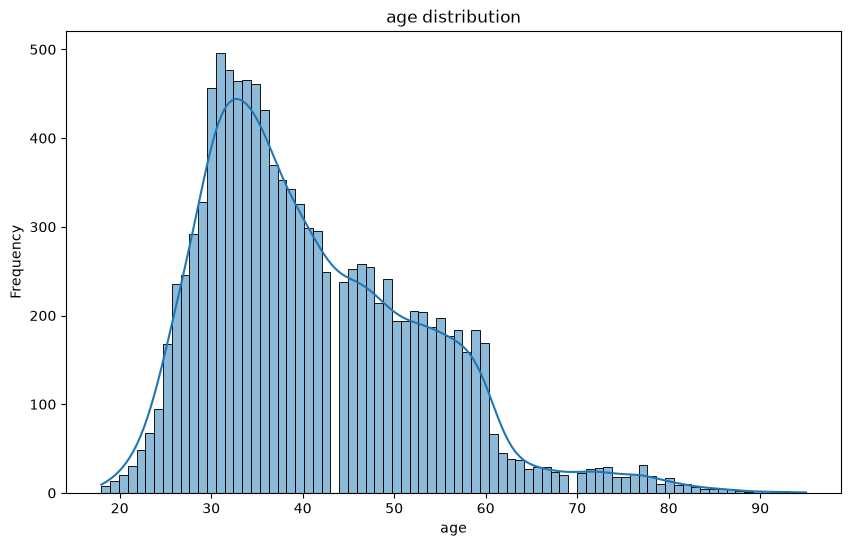

In [17]:
plt.figure(figsize=(10,6))
sns.histplot(df['age'],bins=80, kde=True)  
plt.title("age distribution")
plt.xlabel("age")
plt.ylabel("Frequency")
plt.show()

--- 'unknown' Value Counts per Column ---
job         : 70 rows (0.63%)
marital     : 0 rows (0.00%)
education   : 497 rows (4.45%)
default     : 0 rows (0.00%)
housing     : 0 rows (0.00%)
loan        : 0 rows (0.00%)
contact     : 2346 rows (21.02%)
poutcome    : 8326 rows (74.59%)


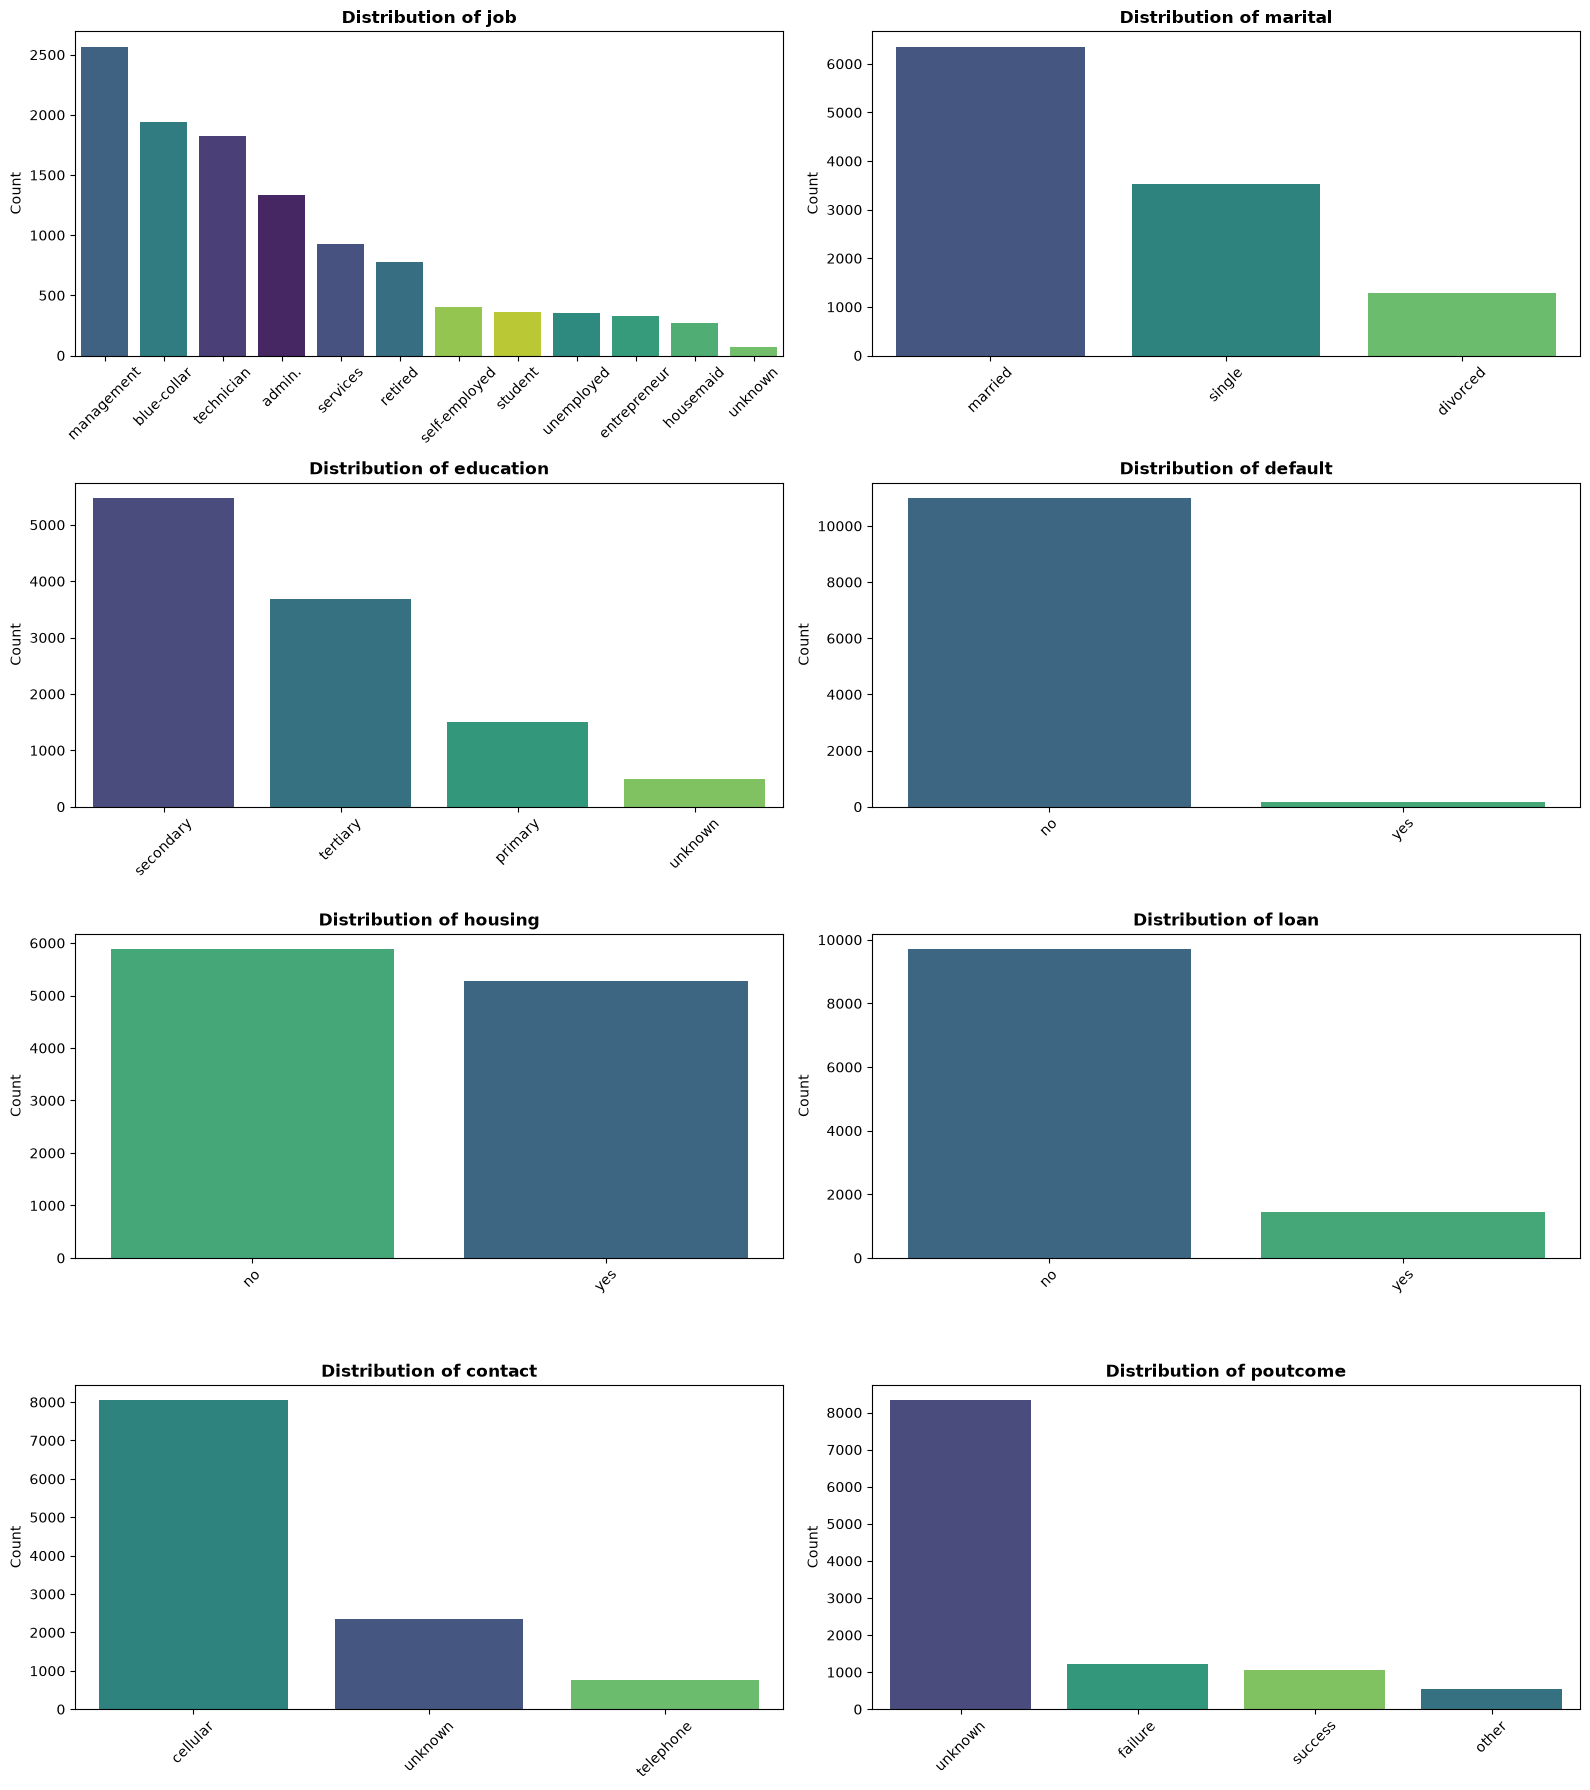

In [18]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome']

# 2. Check exact counts of 'unknown' values per feature
print("--- 'unknown' Value Counts per Column ---")
for col in cat_cols:
    unknown_count = (df[col] == 'unknown').sum()
    pct = (unknown_count / len(df)) * 100
    print(f"{col:12s}: {unknown_count} rows ({pct:.2f}%)")

# 3. Plot grid of countplots
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    # Sort categories by frequency for better readability
    order = df[col].value_counts().index
    
    sns.countplot(
        data=df, 
        x=col, 
        hue = col,
        order=order, 
        ax=axes[i], 
        palette="viridis"
    )
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

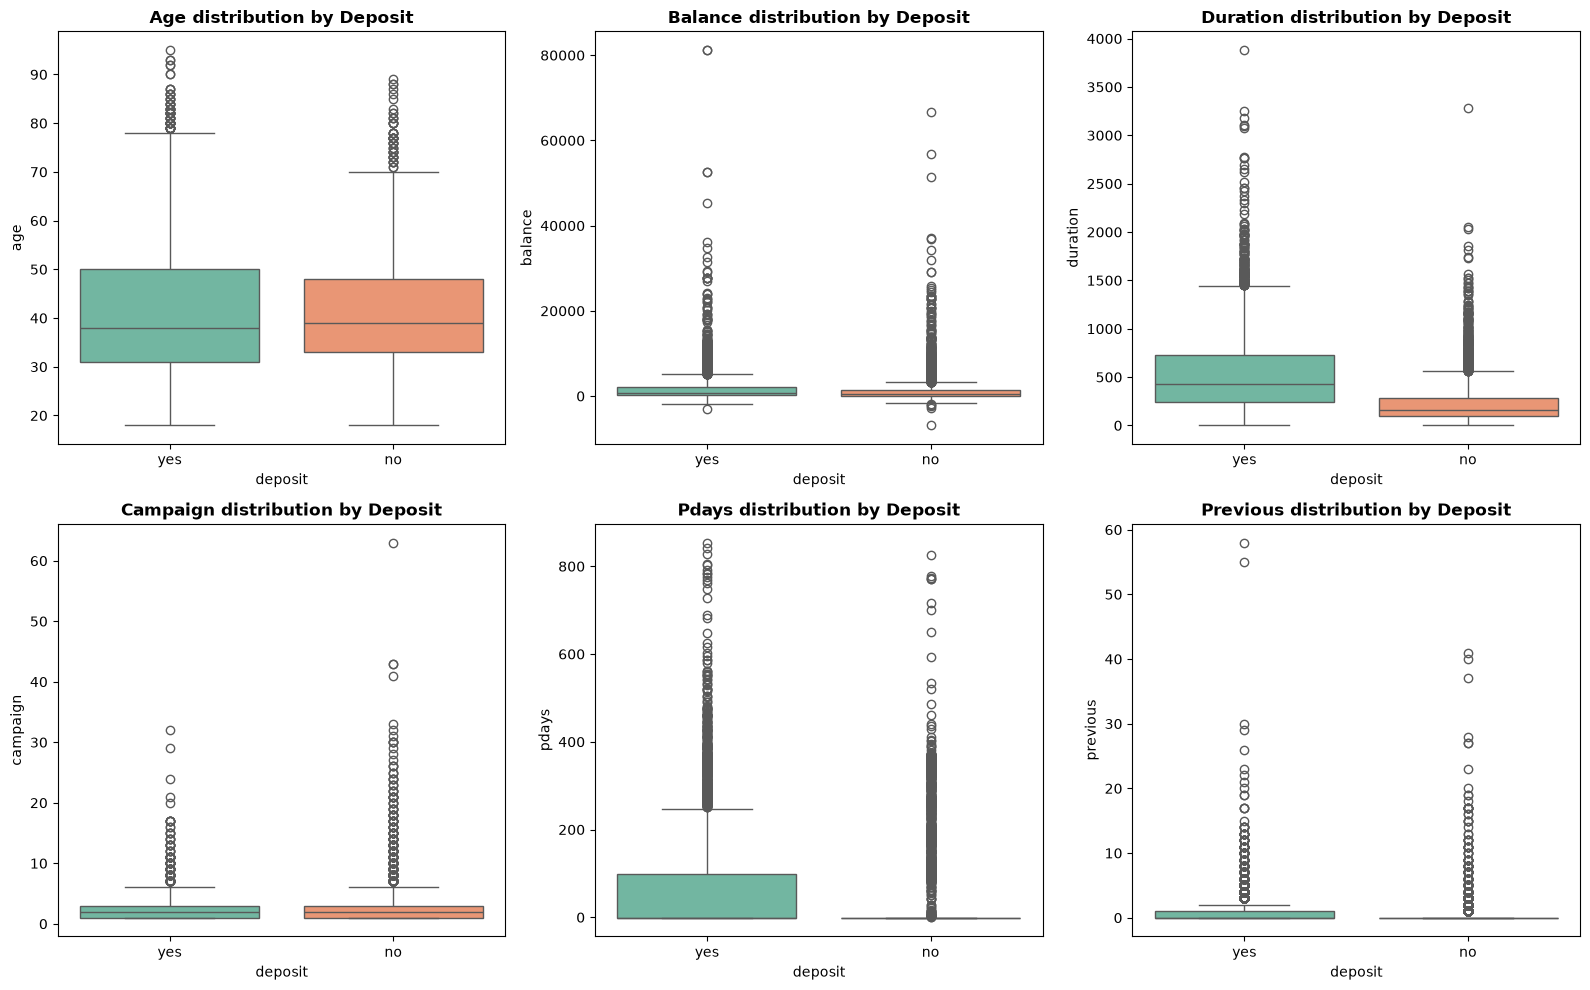

In [21]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(
        data=df, 
        x='deposit', 
        y=col, 
        hue = 'deposit',
        ax=axes[i], 
        palette='Set2'
    )
    axes[i].set_title(f'{col.capitalize()} distribution by Deposit', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


# Bivariate

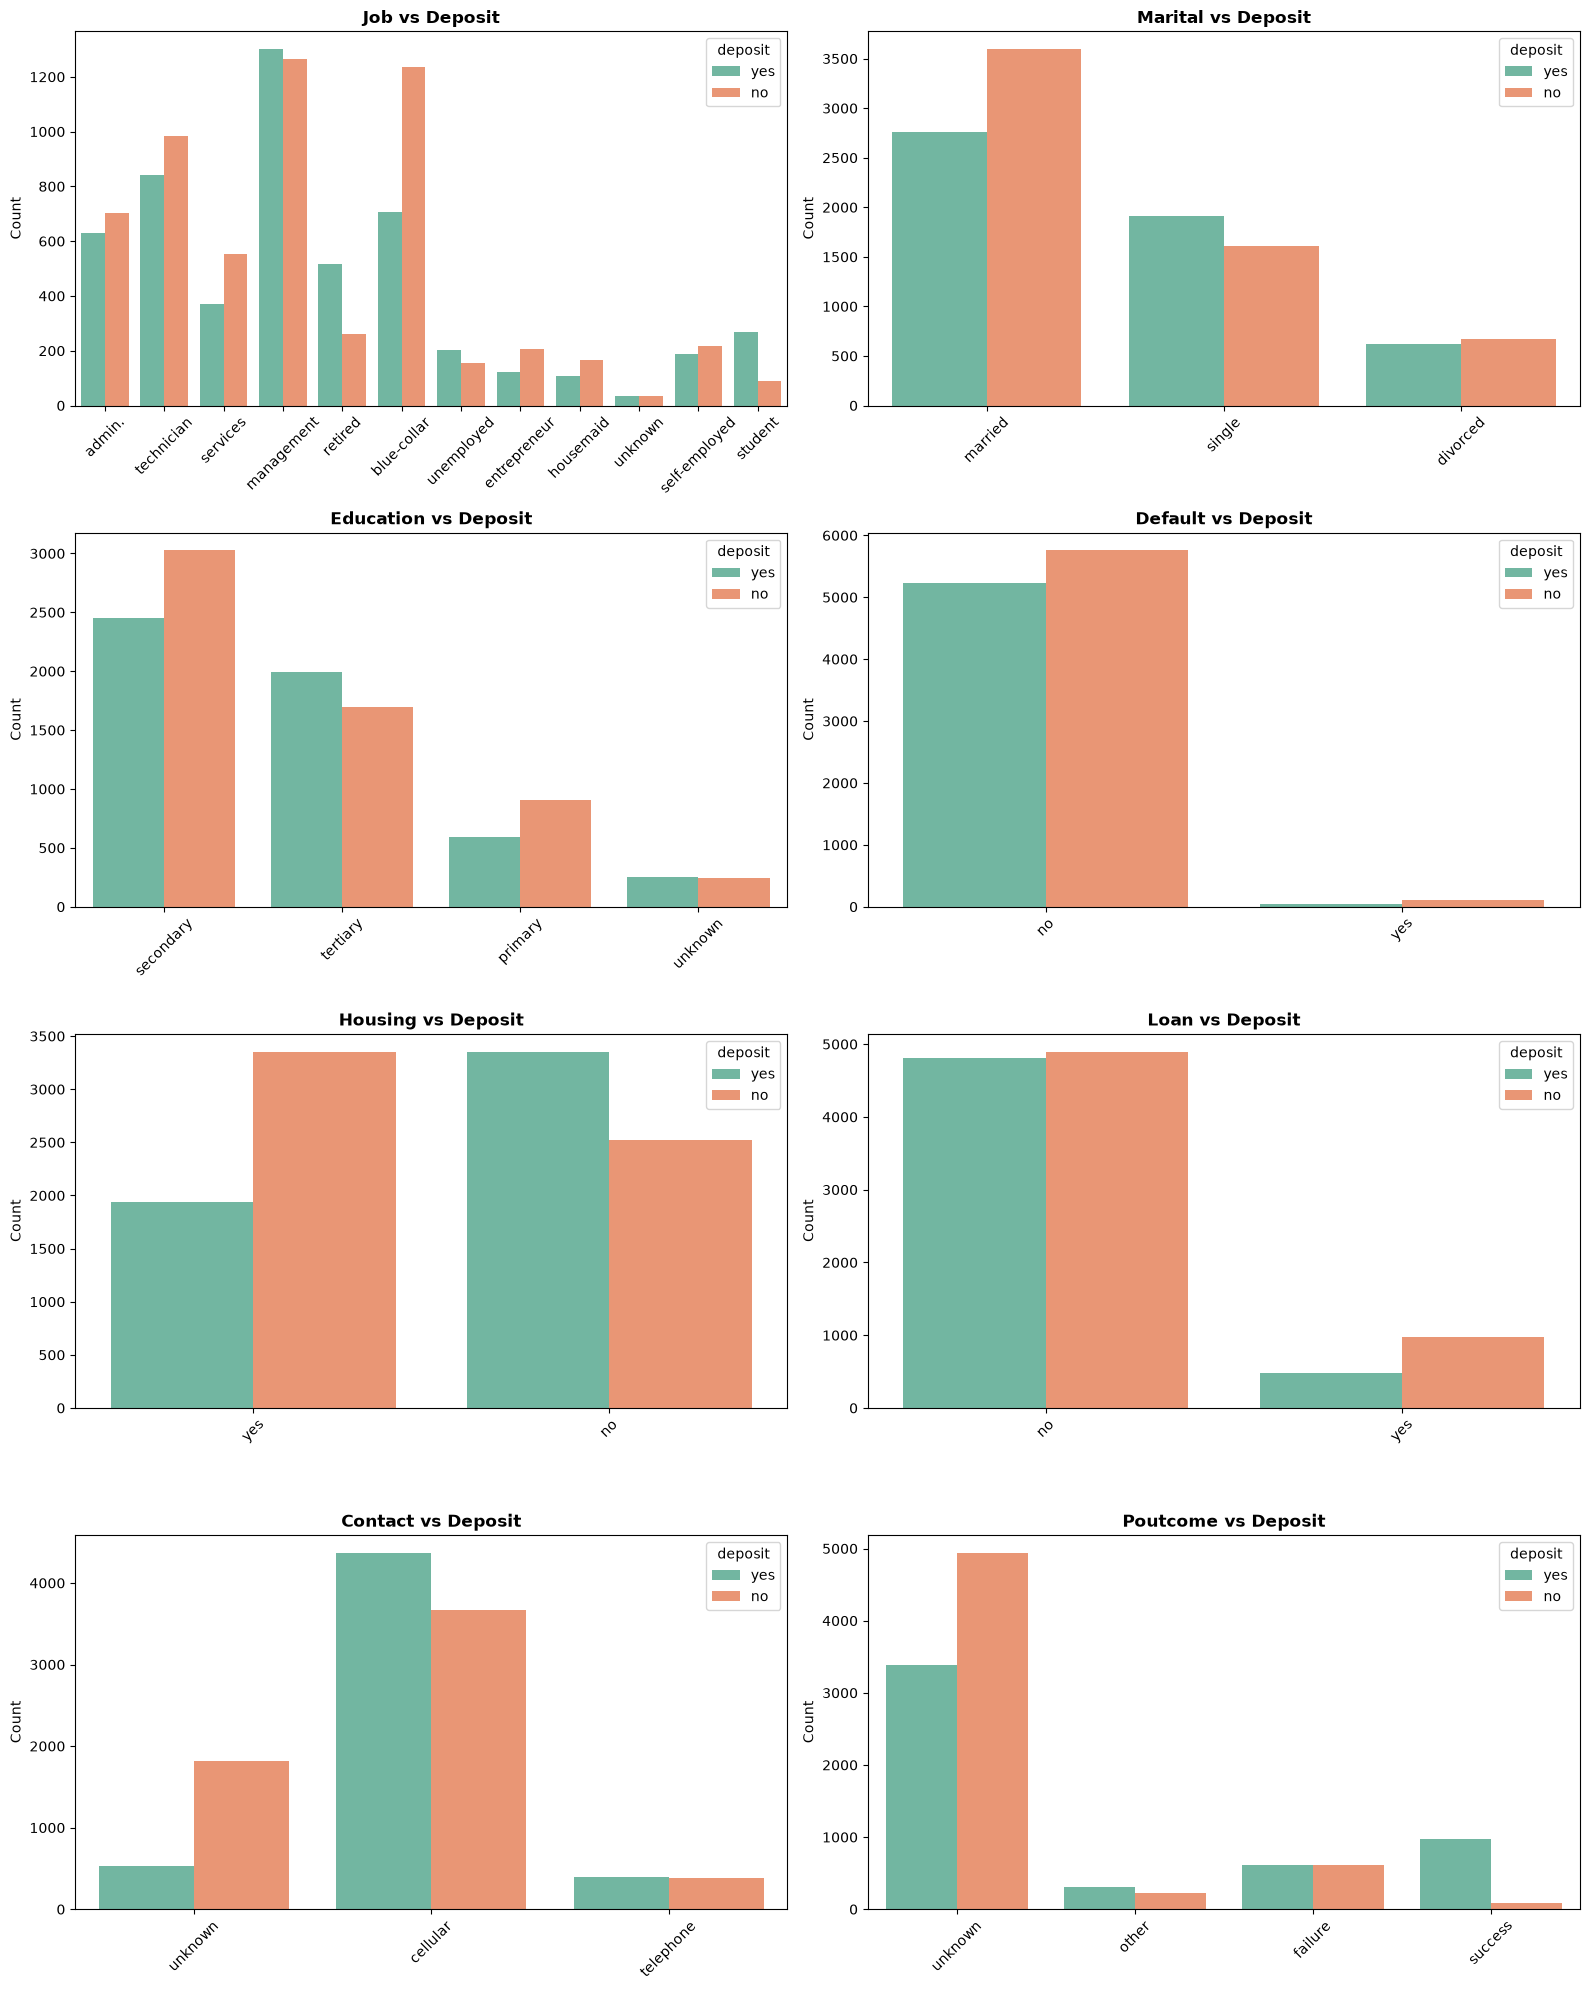

In [19]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.countplot(
        data=df, 
        x=col, 
        hue='deposit', 
        ax=axes[i], 
        palette='Set2'
    )
    axes[i].set_title(f'{col.capitalize()} vs Deposit', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=45)

# Remove the unused 8th subplot


plt.tight_layout()
plt.show()

# Step 1. Import libraries and separate X and y

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [16]:
independent = dataset.drop('Subscribe', axis=1)

dependent = dataset['Subscribe']

print(independent.shape)
print(dependent.shape)

(11162, 40)
(11162,)


In [17]:
independent

,Age,Education,Default,Balance,Housing_Loan,Personal_Loan,Last_Contact_Day,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,...,Last_Contact_Month_jul,Last_Contact_Month_jun,Last_Contact_Month_mar,Last_Contact_Month_may,Last_Contact_Month_nov,Last_Contact_Month_oct,Last_Contact_Month_sep,Previous_Campaign_Outcome_other,Previous_Campaign_Outcome_success,Previous_Campaign_Outcome_unknown
0,59,1,0,2343,1,0,5,1042,1,-1,...,0,0,0,1,0,0,0,0,0,1
1,56,1,0,45,0,0,5,1467,1,-1,...,0,0,0,1,0,0,0,0,0,1
2,41,1,0,1270,1,0,5,1389,1,-1,...,0,0,0,1,0,0,0,0,0,1
3,55,1,0,2476,1,0,5,579,1,-1,...,0,0,0,1,0,0,0,0,0,1
4,54,2,0,184,0,0,5,673,2,-1,...,0,0,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,0,0,1,1,0,20,257,1,-1,...,0,0,0,0,0,0,0,0,0,1
11158,39,1,0,733,0,0,16,83,4,-1,...,0,1,0,0,0,0,0,0,0,1
11159,32,1,0,29,0,0,19,156,2,-1,...,0,0,0,0,0,0,0,0,0,1
11160,43,1,0,0,0,1,8,9,2,172,...,0,0,0,1,0,0,0,0,0,0


In [18]:
dependent

0        1
1        1
2        1
3        1
4        1
        ..
11157    0
11158    0
11159    0
11160    0
11161    0
Name: Subscribe, Length: 11162, dtype: int64

# Step 2. Split the dataset

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    independent,
    dependent,
    test_size=0.2,
    random_state=42,
    stratify=dependent
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8929, 40)
X_test: (2233, 40)
y_train: (8929,)
y_test: (2233,)


# Step 3. Define the classification algorithms

In [24]:
models = {

    'Logistic Regression': (
        LogisticRegression(max_iter=2000),
        {
            'model__C': [0.01, 0.1, 1, 10, 100],
            'model__solver': ['lbfgs', 'liblinear'],
            'model__class_weight': [None, 'balanced']
        }
    ),

    'SVM Linear': (
        SVC(kernel='linear'),
        {
            'model__C': [0.1, 1, 10, 100],
            'model__class_weight': [None, 'balanced']
        }
    ),

    'SVM Non-Linear': (
        SVC(kernel='rbf'),
        {
            'model__C': [0.1, 1, 10, 100],
            'model__gamma': ['scale', 'auto', 0.01, 0.1, 1],
            'model__class_weight': [None, 'balanced']
        }
    ),

    'KNN': (
        KNeighborsClassifier(),
        {
            'model__n_neighbors': [3, 5, 7, 9, 11],
            'model__weights': ['uniform', 'distance'],
            'model__metric': ['euclidean', 'manhattan']
        }
    ),

    'Naive Bayes': (
        GaussianNB(),
        {
            'model__var_smoothing': np.logspace(-12, -6, 7)
        }
    ),

    'Decision Tree': (
        DecisionTreeClassifier(random_state=42),
        {
            'model__criterion': ['gini', 'entropy'],
            'model__max_depth': [3, 5, 7, 10, None],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4]
        }
    ),

    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {
            'model__n_estimators': [50, 100, 200],
            'model__criterion': ['gini', 'entropy'],
            'model__max_depth': [None, 5, 10, 15],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4],
            'model__class_weight': [None, 'balanced']
        }
    )

}

# Step 4. Create the model comparison function

In [26]:
def best_algorithm(X_train, y_train, X_test, y_test):

    results = []

    trained_models = {}

    reports = {}

    confusion_matrices = {}

    for name, (model, param_grid) in models.items():

        print("\nTraining:", name)

        # Create Pipeline

        pipeline = Pipeline([

            ('selector', SelectKBest(
                score_func=f_classif,
                k=6
            )),

            ('scaler', StandardScaler()),

            ('model', model)

        ])

        # GridSearchCV

        classifier = GridSearchCV(

            pipeline,

            param_grid,

            cv=5,

            scoring='f1_macro',

            refit=True,

            n_jobs=-1,

            verbose=1

        )

        # Train model

        classifier.fit(X_train, y_train)

        # Predict test data

        y_pred = classifier.predict(X_test)

        # Calculate metrics

        accuracy = accuracy_score(y_test, y_pred)

        report = classification_report(

            y_test,

            y_pred,

            output_dict=True,

            zero_division=0

        )

        cm = confusion_matrix(y_test, y_pred)

        # Store results

        trained_models[name] = classifier

        reports[name] = report

        confusion_matrices[name] = cm

        results.append({

            'Algorithm': name,

            'Accuracy': accuracy,

            'Class_0_Precision': report['0']['precision'],

            'Class_0_Recall': report['0']['recall'],

            'Class_0_F1': report['0']['f1-score'],

            'Class_1_Precision': report['1']['precision'],

            'Class_1_Recall': report['1']['recall'],

            'Class_1_F1': report['1']['f1-score'],

            'Macro_F1': report['macro avg']['f1-score'],

            'Weighted_F1': report['weighted avg']['f1-score']

        })

        print("Best Parameters:", classifier.best_params_)

        print("Accuracy:", accuracy)

        print("Macro F1:", report['macro avg']['f1-score'])

    # Convert results into DataFrame

    result_df = pd.DataFrame(results)

    # Sort based on Macro F1

    result_df = result_df.sort_values(

        by='Macro_F1',

        ascending=False

    ).reset_index(drop=True)

    # Identify best algorithm

    best_name = result_df.iloc[0]['Algorithm']

    print("\n========== MODEL COMPARISON ==========")

    print(result_df.to_string(index=False))

    print("\n========== BEST ALGORITHM ==========")

    print(best_name)

    print("\n========== BEST CLASSIFICATION REPORT ==========")

    print(pd.DataFrame(reports[best_name]).transpose())

    print("\n========== BEST CONFUSION MATRIX ==========")

    print(confusion_matrices[best_name])

    return (

        result_df,

        trained_models,

        reports,

        confusion_matrices,

        best_name

    )

# Step 5. Execute the model comparison

In [27]:
result_df, trained_models, reports, confusion_matrices, best_name = best_algorithm(

    X_train,

    y_train,

    X_test,

    y_test

)


Training: Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'model__C': 1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Accuracy: 0.7948947604120018
Macro F1: 0.7933510337358356

Training: SVM Linear
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Accuracy: 0.7966860725481415
Macro F1: 0.794957955319538

Training: SVM Non-Linear
Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters: {'model__C': 10, 'model__class_weight': None, 'model__gamma': 1}
Accuracy: 0.8011643528884909
Macro F1: 0.8007884457732555

Training: KNN
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'model__metric': 'euclidean', 'model__n_neighbors': 11, 'model__weights': 'uniform'}
Accuracy: 0.793999104343932
Macro F1: 0.7935768016964331

Training: Naive Bayes
Fitting 5 folds for each of 7 candidates, totalling 35 fits


# Step 6. Display the best algorithm's confusion matrix

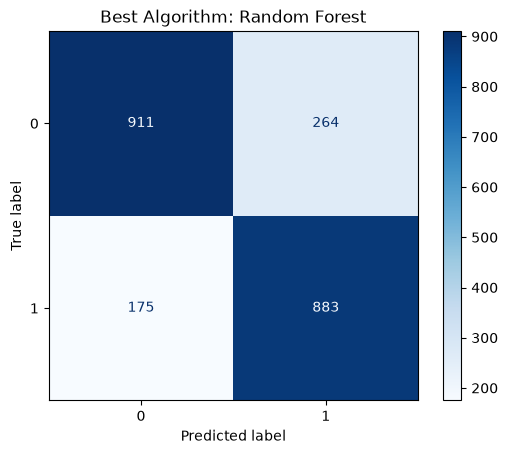

In [28]:
best_cm = confusion_matrices[best_name]

disp = ConfusionMatrixDisplay(

    confusion_matrix=best_cm,

    display_labels=[0, 1]

)

disp.plot(cmap='Blues')

plt.title("Best Algorithm: " + best_name)

plt.show()

# Step 7. Identify the six selected features

In [33]:
# Extract the best trained pipeline

best_pipeline = trained_models[best_name].best_estimator_


# Extract selected feature names

selector = best_pipeline.named_steps['selector']

selected_features = X_train.columns[
    selector.get_support()
]


print("Best Algorithm:", best_name)

print("\nSelected Features:")

print(selected_features.tolist())

print("\nNumber of Features:", len(selected_features))

Best Algorithm: Random Forest

Selected Features:
['Housing_Loan', 'Duration', 'Contact_unknown', 'Last_Contact_Month_may', 'Previous_Campaign_Outcome_success', 'Previous_Campaign_Outcome_unknown']

Number of Features: 6


# Step 8. Evaluate the best trained model

In [36]:
# Use the best trained Pipeline

final_model = best_pipeline


# Predict test data

y_pred = final_model.predict(X_test)


# Accuracy

final_accuracy = accuracy_score(y_test, y_pred)


print("Best Algorithm:", best_name)

print("\nFinal Accuracy:", final_accuracy)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred))

Best Algorithm: Random Forest

Final Accuracy: 0.8034034930586654

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.78      0.81      1175
           1       0.77      0.83      0.80      1058

    accuracy                           0.80      2233
   macro avg       0.80      0.80      0.80      2233
weighted avg       0.81      0.80      0.80      2233


Confusion Matrix:
[[911 264]
 [175 883]]


In [39]:
comparison = pd.DataFrame({

    'Actual': y_test.values,

    'Predicted': y_pred

})

comparison['Correct'] = (

    comparison['Actual'] == comparison['Predicted']

)

print(comparison.head(20))
print(comparison)

    Actual  Predicted  Correct
0        0          1    False
1        1          1     True
2        0          0     True
3        0          0     True
4        1          1     True
5        0          0     True
6        0          0     True
7        1          0    False
8        1          1     True
9        1          1     True
10       0          0     True
11       0          0     True
12       1          1     True
13       0          0     True
14       1          1     True
15       0          0     True
16       0          1    False
17       0          0     True
18       0          0     True
19       1          1     True
      Actual  Predicted  Correct
0          0          1    False
1          1          1     True
2          0          0     True
3          0          0     True
4          1          1     True
...      ...        ...      ...
2228       0          0     True
2229       1          1     True
2230       1          1     True
2231       1       

In [41]:
best_model = best_pipeline.named_steps['model']

best_scaler = best_pipeline.named_steps['scaler']

print(best_model)

RandomForestClassifier(class_weight='balanced', max_depth=5, random_state=42)


In [46]:
X_test.head(2)

,Age,Education,Default,Balance,Housing_Loan,Personal_Loan,Last_Contact_Day,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,...,Last_Contact_Month_jul,Last_Contact_Month_jun,Last_Contact_Month_mar,Last_Contact_Month_may,Last_Contact_Month_nov,Last_Contact_Month_oct,Last_Contact_Month_sep,Previous_Campaign_Outcome_other,Previous_Campaign_Outcome_success,Previous_Campaign_Outcome_unknown
8220,32,2,0,393,0,0,28,458,2,-1,...,0,0,0,0,0,0,0,0,0,1
2521,36,1,0,376,0,0,13,479,1,-1,...,0,0,0,0,0,0,0,0,0,1


In [47]:
y_test.head(2)

8220    0
2521    1
Name: Subscribe, dtype: int64

In [48]:
pd.set_option('display.max_columns', None)

display(X_test)

,Age,Education,Default,Balance,Housing_Loan,Personal_Loan,Last_Contact_Day,Duration,Current_Campaign_Contacts,Days_Since_Previous_Contact,Previous_Campaign_Contacts,Job_blue-collar,Job_entrepreneur,Job_housemaid,Job_management,Job_retired,Job_self-employed,Job_services,Job_student,Job_technician,Job_unemployed,Job_unknown,Marital_married,Marital_single,Contact_telephone,Contact_unknown,Last_Contact_Month_aug,Last_Contact_Month_dec,Last_Contact_Month_feb,Last_Contact_Month_jan,Last_Contact_Month_jul,Last_Contact_Month_jun,Last_Contact_Month_mar,Last_Contact_Month_may,Last_Contact_Month_nov,Last_Contact_Month_oct,Last_Contact_Month_sep,Previous_Campaign_Outcome_other,Previous_Campaign_Outcome_success,Previous_Campaign_Outcome_unknown
8220,32,2,0,393,0,0,28,458,2,-1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1
2521,36,1,0,376,0,0,13,479,1,-1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
7949,52,1,0,722,0,0,26,99,2,185,3,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
7879,35,1,1,-202,1,0,20,268,3,-1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1
616,41,1,0,-190,0,1,29,808,3,-1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11141,32,1,0,130,1,0,6,302,2,-1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
3589,65,1,0,952,0,0,2,310,1,-1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1
4200,35,1,0,2201,0,0,12,350,1,-1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1959,49,2,0,85,1,0,14,590,5,359,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0


In [53]:
new_customer = pd.DataFrame({

    'Housing_Loan': [0],

    'Duration': [479],

    'Contact_unknown': [0],

    'Last_Contact_Month_may': [0],

    'Previous_Campaign_Outcome_success': [0],

    'Previous_Campaign_Outcome_unknown': [1]

})

In [54]:
new_customer = new_customer[selected_features]

In [55]:
new_customer_scaled = best_scaler.transform(new_customer)

C:\anaconda3\envs\machineLearning\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [56]:
prediction = best_model.predict(new_customer_scaled)

if prediction[0] == 1:

    print("Customer is likely to Subscribe")

else:

    print("Customer is not likely to Subscribe")

Customer is likely to Subscribe
